# Hands-On Supervised Machine Learning: Regression Harga Rumah

Tujuan praktikum: memahami supervised learning, membaca data, melatih model regresi, membuat prediksi, mengevaluasi tiga model, dan memperbaiki Decision Tree.

Estimasi live coding: 90–120 menit. Jalankan sel dari atas ke bawah. Setiap angka harga memakai satuan **juta rupiah**.

Dataset ini **sintetis**, dibuat untuk belajar, dan **tidak mewakili harga pasar aktual**.

## 1. Konsep dasar

**AI** adalah bidang yang membuat sistem dapat mengerjakan tugas yang biasanya memerlukan kecerdasan. **Machine Learning (ML)** adalah bagian AI yang mempelajari pola dari data. **Deep Learning (DL)** adalah bagian ML yang memakai jaringan saraf berlapis. Di sini kita menggunakan ML klasik.

Pada **supervised learning**, contoh data sudah memiliki jawaban. Kolom masukan disebut **feature**; jawaban yang ingin diprediksi disebut **target**. Karena harga berupa angka kontinu, tugas ini adalah **regression**.

Model belajar dengan menyesuaikan parameter agar prediksinya dekat dengan target pada data training. Kemampuan sebenarnya diperiksa pada data yang belum dipakai untuk training.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style="whitegrid")
data_path = Path("datasets/harga_rumah.csv")
df = pd.read_csv(data_path)
features = ["luas_rumah", "jumlah_kamar", "usia_bangunan", "jarak_pusat_kota"]
target = "harga_rumah"
print(f"Ukuran dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

Ukuran dataset: 500 baris, 5 kolom


## 2. Kenali dataset

Empat feature menggambarkan luas rumah (40–250 m²), jumlah kamar (1–5), usia bangunan (0–35 tahun), dan jarak dari pusat kota (1–25 km). Targetnya adalah harga rumah. Target tidak boleh dimasukkan ke feature karena itu akan membocorkan jawaban kepada model.

In [2]:
df.head(10)

,luas_rumah,jumlah_kamar,usia_bangunan,jarak_pusat_kota,harga_rumah
0,58,1,29,7.25,316.17
1,203,4,26,8.74,1158.68
2,178,5,20,6.82,1094.06
3,132,5,31,12.52,774.24
4,131,2,4,17.40,746.26
5,221,3,33,6.48,1301.49
6,58,3,30,8.94,459.85
7,187,2,18,23.33,1006.86
8,82,2,26,2.17,626.34
9,59,2,18,12.06,470.48


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   luas_rumah        500 non-null    int64  
 1   jumlah_kamar      500 non-null    int64  
 2   usia_bangunan     500 non-null    int64  
 3   jarak_pusat_kota  500 non-null    float64
 4   harga_rumah       500 non-null    float64
dtypes: float64(2), int64(3)
memory usage: 19.7 KB


In [4]:
df.describe().round(2)

,luas_rumah,jumlah_kamar,usia_bangunan,jarak_pusat_kota,harga_rumah
count,500.00,500.00,500.00,500.00,500.00
mean,144.83,3.04,17.80,12.91,882.33
std,60.35,1.43,10.43,7.03,309.73
min,41.00,1.00,0.00,1.01,170.61
25%,95.00,2.00,9.00,6.72,610.65
50%,144.00,3.00,18.00,12.57,910.00
75%,198.00,4.00,27.00,19.04,1143.49
max,250.00,5.00,35.00,24.99,1502.29


In [5]:
df.isnull().sum().rename('jumlah_missing')

luas_rumah          0
jumlah_kamar        0
usia_bangunan       0
jarak_pusat_kota    0
harga_rumah         0
Name: jumlah_missing, dtype: int64

Periksa rentang pada tabel statistik dan jumlah nilai kosong. Dataset sintetis ini dibuat lengkap, sehingga kita tidak memerlukan imputasi atau preprocessing yang harus di-fit.

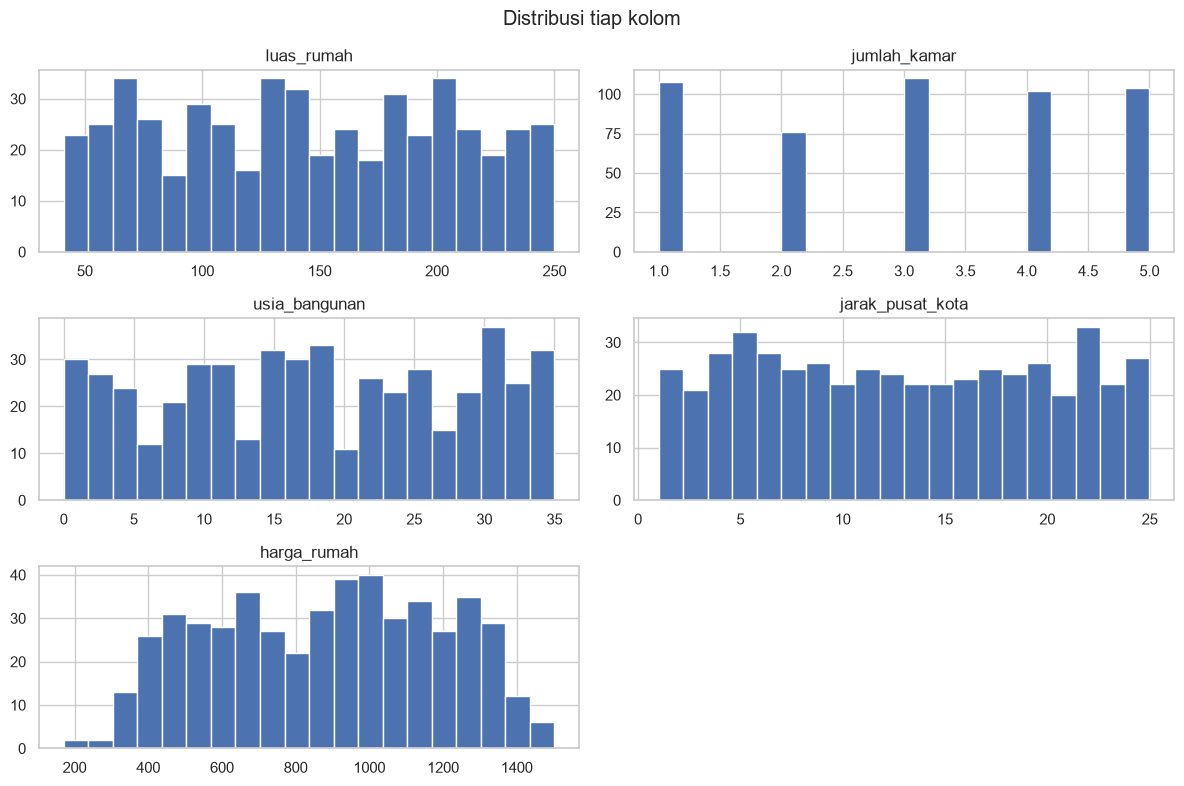

In [6]:
df.hist(figsize=(12, 8), bins=20, edgecolor="white")
plt.suptitle("Distribusi tiap kolom")
plt.tight_layout()
plt.show()

Histogram menunjukkan sebaran nilai. Feature dibuat dalam rentang tertentu, sedangkan harga terbentuk dari gabungan feature dan noise.

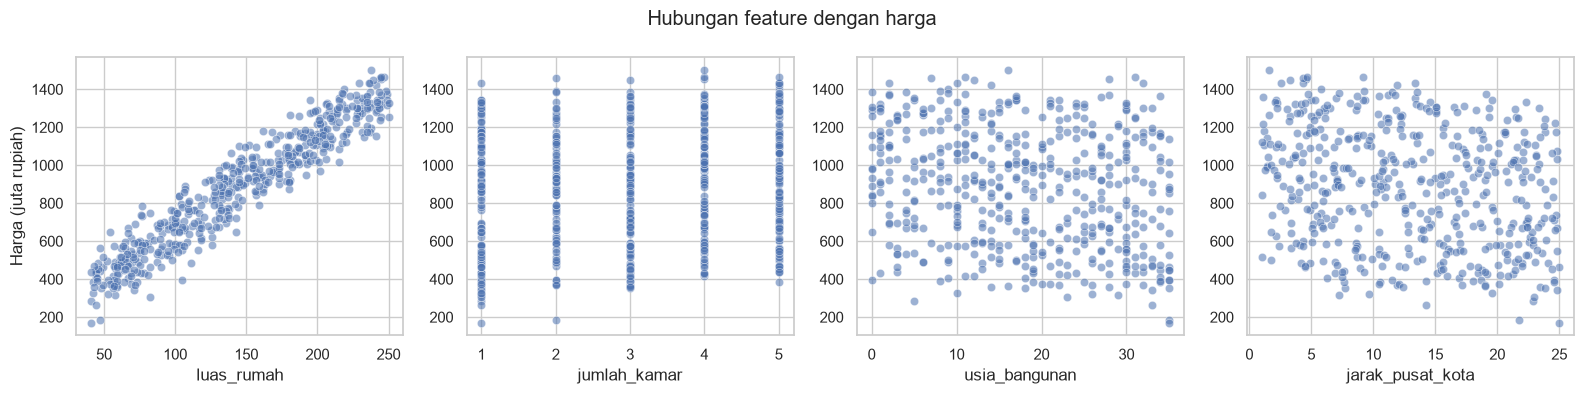

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, feature in zip(axes, features):
    sns.scatterplot(data=df, x=feature, y=target, ax=ax, alpha=0.55)
    ax.set_ylabel("Harga (juta rupiah)" if ax is axes[0] else "")
fig.suptitle("Hubungan feature dengan harga")
plt.tight_layout()
plt.show()

Luas yang lebih besar cenderung menaikkan harga. Usia bangunan dan jarak dari pusat kota cenderung menurunkannya. Hubungan satu feature bisa tampak tersebar karena tiga feature lain dan noise juga berpengaruh.

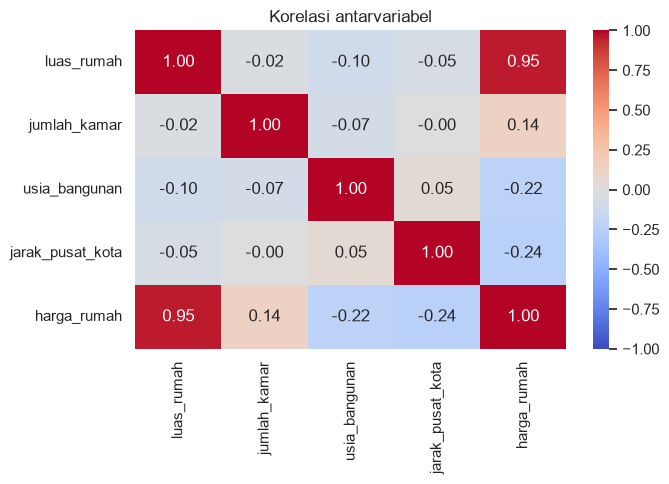

In [8]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi antarvariabel")
plt.tight_layout()
plt.show()

Korelasi positif berarti dua variabel cenderung naik bersama; korelasi negatif berarti bergerak berlawanan. Korelasi tidak membuktikan sebab-akibat.

**Mini challenge 1:** feature mana yang paling berkorelasi dengan harga? Cocokkah dengan scatter plot?

## 3. Training dan prediksi

Kita membagi data menjadi **80% training** dan **20% testing**. Pemisahan dilakukan sebelum model dilatih. `X_train` berisi feature untuk belajar, `y_train` berisi jawabannya, sedangkan `X_test` dan `y_test` disimpan untuk evaluasi.

In [9]:
X = df[features]
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Feature training:", X_train.shape)
print("Feature testing:", X_test.shape)
print("Target training:", y_train.shape)
print("Target testing:", y_test.shape)

Feature training: (400, 4)
Feature testing: (100, 4)
Target training: (400,)
Target testing: (100,)


Sebagai demonstrasi awal, kita latih model dengan luas saja. Model utama setelahnya memakai keempat feature. Semua prediksi untuk evaluasi dibuat pada test set.

In [10]:
model_luas = LinearRegression()
model_luas.fit(X_train[["luas_rumah"]], y_train)
pred_luas = model_luas.predict(X_test[["luas_rumah"]])
print(f"RMSE dengan luas saja: {mean_squared_error(y_test, pred_luas) ** 0.5:.2f}")

RMSE dengan luas saja: 92.95


In [11]:
model_linear = LinearRegression()
model_linear.fit(X_train, y_train)
pred_linear = model_linear.predict(X_test)
hasil_prediksi = pd.DataFrame({
    "aktual": y_test.to_numpy(),
    "prediksi": pred_linear,
    "selisih": y_test.to_numpy() - pred_linear,
})
hasil_prediksi.head(10).round(2)

,aktual,prediksi,selisih
0,1369.24,1409.08,-39.84
1,404.28,402.17,2.11
2,1251.07,1285.01,-33.94
3,1038.98,1003.55,35.43
4,1284.46,1332.76,-48.30
5,1183.28,1187.05,-3.77
6,1051.36,1099.40,-48.04
7,1289.67,1194.19,95.48
8,414.59,479.96,-65.37
9,1332.28,1289.21,43.07


Selisih adalah harga aktual dikurangi prediksi. Prediksi yang baik mendekati nilai aktual, tetapi noise membuatnya tidak selalu tepat.

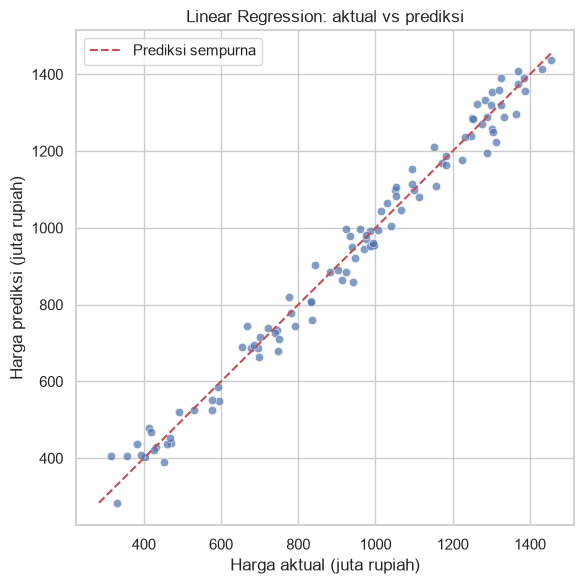

In [12]:
plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=pred_linear, alpha=0.7)
limits = [min(y_test.min(), pred_linear.min()), max(y_test.max(), pred_linear.max())]
plt.plot(limits, limits, "r--", label="Prediksi sempurna")
plt.xlabel("Harga aktual (juta rupiah)")
plt.ylabel("Harga prediksi (juta rupiah)")
plt.title("Linear Regression: aktual vs prediksi")
plt.legend()
plt.tight_layout()
plt.show()

Semakin dekat titik ke garis merah, semakin kecil error prediksi.

In [13]:
rumah_baru = pd.DataFrame([{
    "luas_rumah": 120,
    "jumlah_kamar": 3,
    "usia_bangunan": 8,
    "jarak_pusat_kota": 5,
}])
print(f"Prediksi rumah baru: {model_linear.predict(rumah_baru)[0]:.2f} juta rupiah")

Prediksi rumah baru: 858.46 juta rupiah


**Mini challenge 2:** ubah jarak rumah baru menjadi 20 km. Bandingkan prediksi sebelum dan sesudahnya.

## 4. Evaluasi tiga model

**MAE** adalah rata-rata nilai absolut error. **MSE** adalah rata-rata kuadrat error, sehingga error besar mendapat penalti lebih tinggi. **RMSE** adalah akar MSE dan kembali ke satuan juta rupiah. Ketiganya lebih baik jika lebih kecil. **R²** mengukur bagian variasi harga yang dijelaskan model; pada kasus ini lebih tinggi lebih baik.

Decision Tree membagi data menjadi aturan bercabang. Random Forest menggabungkan banyak tree. Kita bandingkan keduanya dengan Linear Regression pada test set yang sama.

In [14]:
models = {
    "Linear Regression": model_linear,
    "Decision Tree": DecisionTreeRegressor(max_depth=6, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
}

rows = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "MSE": mean_squared_error(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "R²": r2_score(y_test, pred),
    })

metrics = pd.DataFrame(rows).set_index("Model")
metrics.round(3)

,MAE,MSE,RMSE,R²
Model,,,,
Linear Regression,33.035,1640.825,40.507,0.983
Decision Tree,64.891,6958.377,83.417,0.929
Random Forest,42.365,2794.151,52.860,0.972


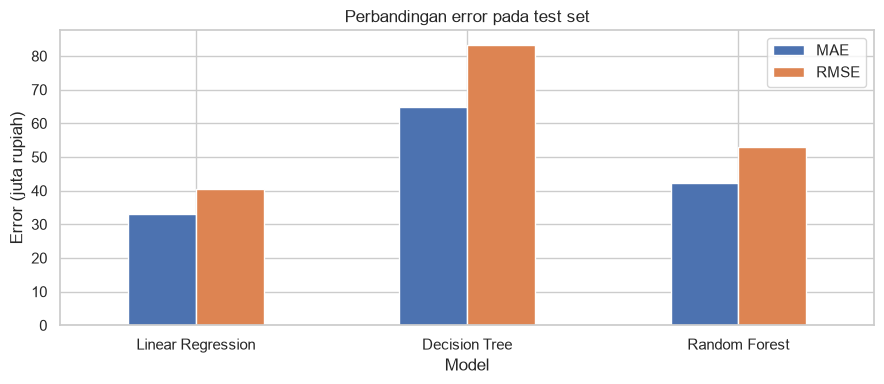

In [15]:
metrics[["MAE", "RMSE"]].plot.bar(figsize=(9, 4))
plt.ylabel("Error (juta rupiah)")
plt.title("Perbandingan error pada test set")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Batang lebih pendek berarti error test lebih kecil. Nilai pada tabel dan grafik berasal langsung dari hasil eksekusi, bukan angka contoh.

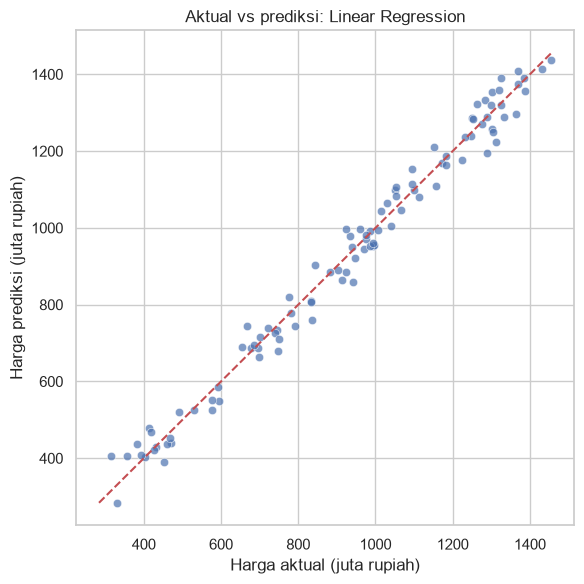

RMSE test terendah: Linear Regression (40.51 juta rupiah)


In [16]:
best_name = metrics["RMSE"].idxmin()
best_pred = predictions[best_name]
plt.figure(figsize=(6, 6))
sns.scatterplot(x=y_test, y=best_pred, alpha=0.7)
limits = [min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())]
plt.plot(limits, limits, "r--")
plt.xlabel("Harga aktual (juta rupiah)")
plt.ylabel("Harga prediksi (juta rupiah)")
plt.title(f"Aktual vs prediksi: {best_name}")
plt.tight_layout()
plt.show()
print(f"RMSE test terendah: {best_name} ({metrics.loc[best_name, 'RMSE']:.2f} juta rupiah)")

**Underfitting** terjadi jika model terlalu sederhana untuk menangkap pola. **Overfitting** terjadi jika model terlalu mengikuti data training dan performanya memburuk pada data baru. Membandingkan error training dengan validation membantu melihatnya.

**Mini challenge 3:** ubah `max_depth` Decision Tree menjadi 2, lalu bandingkan MAE dan RMSE.

## 5. Meningkatkan Decision Tree

Parameter adalah nilai yang dipelajari model dari data; hyperparameter ditentukan sebelum training. `max_depth` dan `min_samples_leaf` adalah hyperparameter Decision Tree.

Untuk tuning manual, data training dipecah lagi menjadi data fit dan validation. **Test set tetap disimpan** sampai pemilihan model selesai.

In [17]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42
)

tuning_rows = []
for depth in [2, 4, 6, 10]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree.fit(X_fit, y_fit)
    tuning_rows.append({
        "max_depth": depth,
        "train_rmse": mean_squared_error(y_fit, tree.predict(X_fit)) ** 0.5,
        "validation_rmse": mean_squared_error(y_val, tree.predict(X_val)) ** 0.5,
    })

tuning = pd.DataFrame(tuning_rows)
tuning.round(3)

,max_depth,train_rmse,validation_rmse
0,2,113.157,121.815
1,4,68.762,102.373
2,6,35.268,95.081
3,10,8.187,90.226


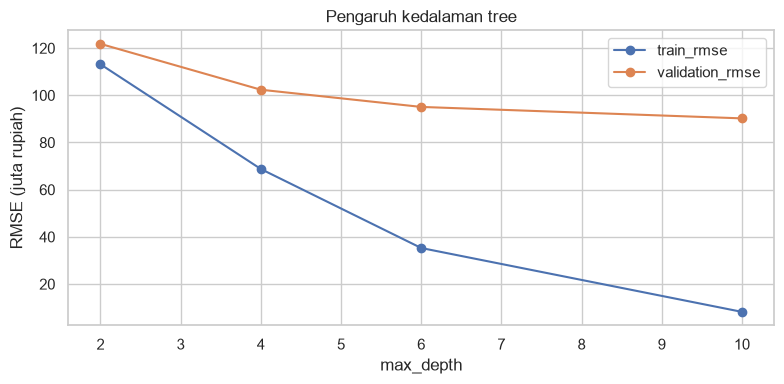

In [18]:
tuning.plot(x="max_depth", y=["train_rmse", "validation_rmse"],
            marker="o", figsize=(8, 4))
plt.ylabel("RMSE (juta rupiah)")
plt.title("Pengaruh kedalaman tree")
plt.tight_layout()
plt.show()

Saat tree makin dalam, error training biasanya turun. Jika error validation naik lagi, model mulai overfitting. Tree yang terlalu dangkal bisa underfitting.

**Cross-validation** mengulang training dan validation pada beberapa lipatan data training. `GridSearchCV` mencoba kombinasi hyperparameter dan memilih yang rata-rata error validasinya paling rendah.

In [19]:
grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid={
        "max_depth": [2, 4, 6, 10, None],
        "min_samples_leaf": [1, 3, 5],
    },
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
grid.fit(X_train, y_train)
print("Hyperparameter terbaik:", grid.best_params_)
print(f"RMSE cross-validation: {-grid.best_score_:.2f} juta rupiah")

Hyperparameter terbaik: {'max_depth': None, 'min_samples_leaf': 3}
RMSE cross-validation: 77.91 juta rupiah


Setelah kombinasi dipilih melalui cross-validation pada data training, baru kita evaluasi sekali pada test set yang belum digunakan dalam pemilihan.

In [20]:
test_pred = grid.best_estimator_.predict(X_test)
hasil_akhir = pd.Series({
    "MAE": mean_absolute_error(y_test, test_pred),
    "MSE": mean_squared_error(y_test, test_pred),
    "RMSE": mean_squared_error(y_test, test_pred) ** 0.5,
    "R²": r2_score(y_test, test_pred),
}, name="Decision Tree terbaik")
hasil_akhir.round(3)

MAE       58.624
MSE     5113.671
RMSE      71.510
R²         0.948
Name: Decision Tree terbaik, dtype: float64

Bandingkan RMSE Decision Tree hasil tuning dengan tiga model sebelumnya. Tuning memperbaiki konfigurasi satu model, tetapi tidak menjamin model itu mengalahkan model lain.

**Mini challenge 4:** tambahkan `min_samples_split: [2, 5, 10]` ke grid. Apakah hyperparameter terbaik atau RMSE cross-validation berubah?

### Ringkasan

Alur kerja regresi: pahami data → pisahkan feature dan target → split training/test → fit → predict → evaluasi → tuning pada training/validation → evaluasi akhir pada test. Gunakan prediksi hanya sebagai latihan karena data ini sintetis.